<a href="https://colab.research.google.com/github/20more00-sys/Hackathon-/blob/main/Hakathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# تثبيت مكتبة kaggle لو مش موجودة
!pip install -q kaggle

# ارفع ملف kaggle.json بتاعك (من حسابك على Kaggle → Account → Create New API Token)
from google.colab import files
files.upload()   # ارفع kaggle.json هنا

# إعداد الصلاحيات
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# تحميل الداتا
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

# فك الضغط
!unzip -q brain-tumor-mri-dataset.zip -d brain_tumor_data


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 149MB/s]



In [2]:
import os
import matplotlib.pyplot as plt
from collections import Counter

base_dir = "brain_tumor_data"
train_dir = os.path.join(base_dir, "Training")
test_dir  = os.path.join(base_dir, "Testing")

# عدد الصور في كل فئة
def count_images(folder):
    counts = {}
    for class_name in os.listdir(folder):
        class_path = os.path.join(folder, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(os.listdir(class_path))
    return counts

print("Training distribution:")
print(count_images(train_dir))

print("\nTesting distribution:")
print(count_images(test_dir))

Training distribution:
{'notumor': 1400, 'glioma': 1400, 'pituitary': 1400, 'meningioma': 1400}

Testing distribution:
{'notumor': 400, 'glioma': 400, 'pituitary': 400, 'meningioma': 400}


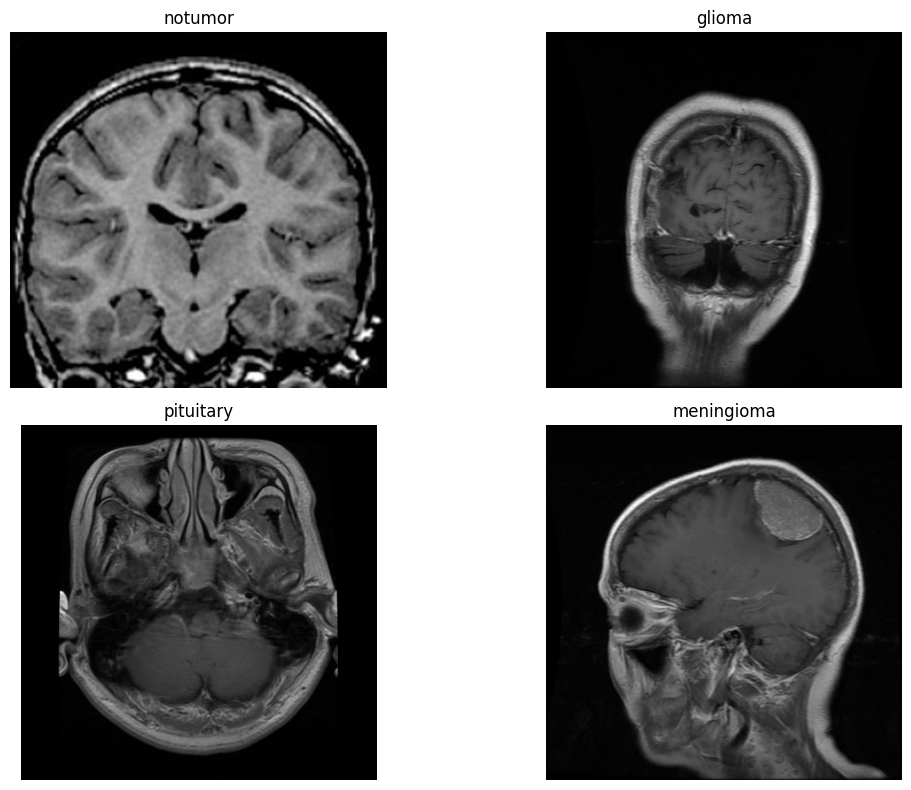

In [3]:
import random
from PIL import Image

def show_samples(folder, num_samples=4):
    classes = os.listdir(folder)

    plt.figure(figsize=(12, 8))
    for i, class_name in enumerate(classes):
        class_path = os.path.join(folder, class_name)
        images = os.listdir(class_path)
        sample_img = random.choice(images)

        img = Image.open(os.path.join(class_path, sample_img))

        plt.subplot(2, 2, i+1)
        plt.imshow(img, cmap='gray')
        plt.title(f"{class_name}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

show_samples(train_dir)

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# المسارات
base_dir = "brain_tumor_data"
train_dir = os.path.join(base_dir, "Training")
test_dir  = os.path.join(base_dir, "Testing")

# إعدادات
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 4

In [5]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.15   # ناخد 15% من الـ Training كـ Validation
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Class indices:", train_generator.class_indices)

Found 4760 images belonging to 4 classes.
Found 840 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [6]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# نجمد الطبقات الأساسية في الأول
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
history = model.fit(
    train_generator,
    epochs=8,
    validation_data=val_generator
)

Epoch 1/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1277s 8s/step - accuracy: 0.3868 - loss: 1.2900 - val_accuracy: 0.4381 - val_loss: 1.1862
Epoch 2/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1248s 8s/step - accuracy: 0.4525 - loss: 1.1559 - val_accuracy: 0.5274 - val_loss: 1.0986
Epoch 3/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1246s 8s/step - accuracy: 0.4855 - loss: 1.1174 - val_accuracy: 0.5607 - val_loss: 1.0759
Epoch 4/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1245s 8s/step - accuracy: 0.4989 - loss: 1.0927 - val_accuracy: 0.6048 - val_loss: 1.0388
Epoch 5/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1242s 8s/step - accuracy: 0.5267 - loss: 1.0669 - val_accuracy: 0.6071 - val_loss: 1.0197
Epoch 6/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1242s 8s/step - accuracy: 0.5334 - loss: 1.0516 - val_accuracy: 0.6155 - val_loss: 0.9673
Epoch 7/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1246s 8s/step - accuracy: 0.5529 - loss: 1.0271 - val_accuracy: 0.6167 - val_loss: 0.9479
Epoch 8/8
149/149 ━━━━━━━━━━━━━━━━━━━━ 1246s 8s/step - accuracy: 0.5519 - loss: 1.0147 - val_accu

In [10]:
# 1. تقييم عام على الـ Test set
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_accuracy*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

50/50 ━━━━━━━━━━━━━━━━━━━━ 336s 7s/step - accuracy: 0.6081 - loss: 1.1998

Test Accuracy: 60.81%
Test Loss: 1.1998


In [11]:
# 2. التنبؤ على كل صور الـ Test
test_generator.reset()
predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# أسماء الفئات
class_names = list(test_generator.class_indices.keys())
print("Class order:", class_names)

50/50 ━━━━━━━━━━━━━━━━━━━━ 353s 7s/step
Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [12]:
# 3. تقرير التصنيف الكامل (مهم جدًا)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


Classification Report:
              precision    recall  f1-score   support

      glioma       0.75      0.29      0.42       400
  meningioma       0.55      0.40      0.46       400
     notumor       0.63      0.85      0.72       400
   pituitary       0.59      0.89      0.71       400

    accuracy                           0.61      1600
   macro avg       0.63      0.61      0.58      1600
weighted avg       0.63      0.61      0.58      1600



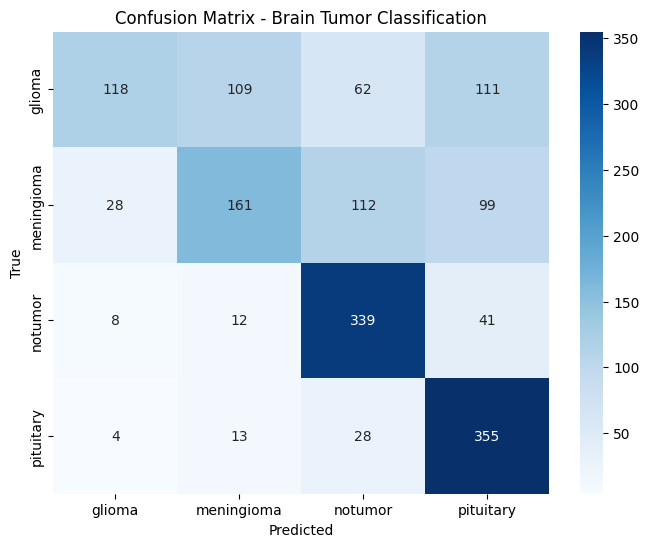

In [13]:
# 4. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Brain Tumor Classification')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# المسارات
base_dir = "brain_tumor_data"
train_dir = os.path.join(base_dir, "Training")
test_dir  = os.path.join(base_dir, "Testing")

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 4

In [5]:
# Data Generators
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.15
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 4760 images belonging to 4 classes.
Found 840 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [6]:
# بناء الموديل من جديد
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False   # في الأول مجمد

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model created successfully")

Model created successfully
